In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers,models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [3]:
df = pd.read_csv("creditcard.csv")
print(df.head())
print(df.shape)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
x = df.drop("Class",axis=1)
y = df["Class"]

In [5]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)

In [6]:
print(x_train.shape)

(227845, 30)


In [7]:
x_train=x_train[y_train==0]
print(x_train.shape)

(227451, 30)


In [8]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [9]:
encoder = models.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(20,activation="relu"),
    layers.Dense(14,activation="relu"),
    layers.Dense(8,activation="relu"),
    layers.Dense(4,activation="relu")
])
decoder = models.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(8,activation="relu"),
    layers.Dense(14,activation="relu"),
    layers.Dense(20,activation="relu"),
    layers.Dense(30,activation="sigmoid")
])
model = models.Sequential([encoder,decoder])

In [10]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
history = model.fit(
    x_train,x_train,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0094 - mae: 0.0555 - val_loss: 0.0044 - val_mae: 0.0351
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0043 - mae: 0.0354 - val_loss: 0.0042 - val_mae: 0.0366
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0029 - mae: 0.0323 - val_loss: 0.0019 - val_mae: 0.0262
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0018 - mae: 0.0259 - val_loss: 0.0018 - val_mae: 0.0261
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0018 - mae: 0.0260 - val_loss: 0.0018 - val_mae: 0.0261
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0018 - mae: 0.0260 - val_loss: 0.0018 - val_mae: 0.0261
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0018 - mae: 0.0260 - val_loss: 0.0018 - val_mae: 0.0259
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0018 - mae: 0.0259 - val_loss: 0.0017 - val_mae: 0.0259
Epoch 9/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - lo

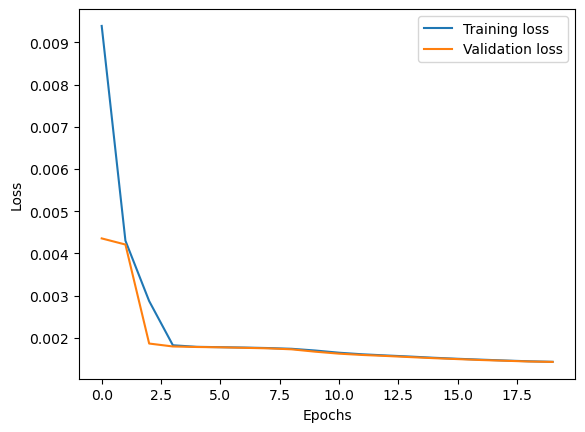

In [11]:
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [12]:
predictions = model.predict(x_train)
train_errors = np.mean(np.square(x_train-predictions),axis=1)
threshold = np.mean(train_errors) + np.std(train_errors)
print("Anomaly threshold:",threshold)

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step
Anomaly threshold: 0.002722197829350405


In [13]:
predictions = model.predict(x_test)
errors = np.mean(np.square(x_test-predictions),axis=1)
anomalies = (errors > threshold).astype(int)
print("Number of detected fraud transactions:",np.sum(anomalies))

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step
Number of detected fraud transactions: 4953


In [14]:
print("Accuracy_score:",accuracy_score(y_test,anomalies))
print("confusion matrix:",confusion_matrix(y_test,anomalies))
print("classification report:",classification_report(y_test,anomalies))

Accuracy_score: 0.9144517397563288
confusion matrix: [[52000  4864]
 [    9    89]]
classification report:               precision    recall  f1-score   support

           0       1.00      0.91      0.96     56864
           1       0.02      0.91      0.04        98

    accuracy                           0.91     56962
   macro avg       0.51      0.91      0.50     56962
weighted avg       1.00      0.91      0.95     56962



In [15]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers,models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

df = pd.read_csv("creditcard.csv")
print(df.head())
print(df.shape)

x = df.drop("Class",axis=1)
y = df["Class"]

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)

print(x_train.shape)

x_train=x_train[y_train==0]
print(x_train.shape)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


encoder = models.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(20,activation="relu"),
    layers.Dense(14,activation="relu"),
    layers.Dense(8,activation="relu"),
    layers.Dense(4,activation="relu")
])
decoder = models.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(8,activation="relu"),
    layers.Dense(14,activation="relu"),
    layers.Dense(20,activation="relu"),
    layers.Dense(30,activation="sigmoid")
])
model = models.Sequential([encoder,decoder])


model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
history = model.fit(
    x_train,x_train,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    shuffle=True
)

plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

predictions = model.predict(x_train)
train_errors = np.mean(np.square(x_train-predictions),axis=1)
threshold = np.mean(train_errors) + np.std(train_errors)
print("Anomaly threshold:",threshold)

predictions = model.predict(x_test)
errors = np.mean(np.square(x_test-predictions),axis=1)
anomalies = (errors > threshold).astype(int)
print("Number of detected fraud transactions:",np.sum(anomalies))


print("Accuracy_score:",accuracy_score(y_test,anomalies))
print("confusion matrix:",confusion_matrix(y_test,anomalies))
print("classification report:",classification_report(y_test,anomalies))

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 